In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import plotly.express as px
import seaborn as sns

In [2]:
pd.options.display.float_format = '{:,.2f}'.format

df_data = pd.read_csv('../Data/nobel_prize_data.csv')

In [14]:
df_data.birth_date = pd.to_datetime(df_data.birth_date)

In [34]:
df_data.head(1)

,year,category,prize,motivation,prize_share,laureate_type,full_name,birth_date,birth_city,birth_country,birth_country_current,sex,organization_name,organization_city,organization_country,ISO,share_pct
0,1901,Chemistry,The Nobel Prize in Chemistry 1901,"""in recognition of the extraordinary services ...",1/1,Individual,Jacobus Henricus van 't Hoff,1852-08-30,Rotterdam,Netherlands,Netherlands,Male,Berlin University,Berlin,Germany,NLD,1.00


---
**Prize Share**

In [29]:
separated_values = df_data.prize_share.astype(str).str.split('/', expand=True)

numerator = pd.to_numeric(separated_values[0])
denomenator = pd.to_numeric(separated_values[1])
df_data['share_pct'] = numerator / denomenator

---
**Male vs Female Winners**

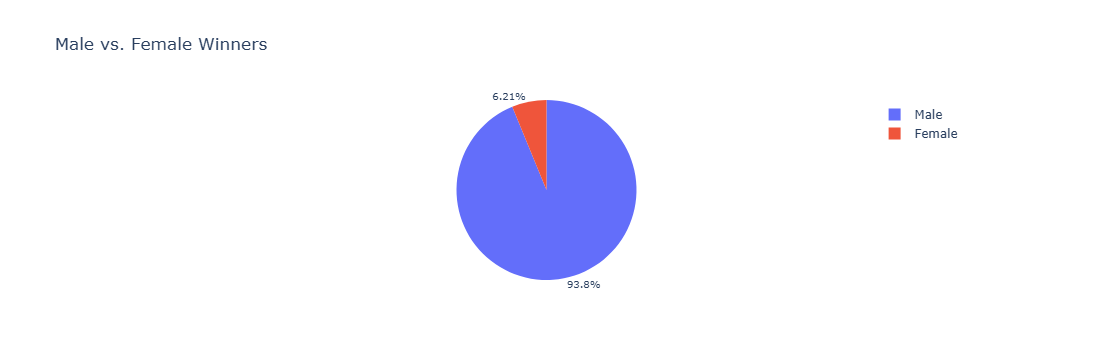

In [33]:
biology = df_data.sex.value_counts()

fig = px.pie(labels=biology.index, values=biology.values , title="Male vs. Female Winners", names=biology.index)

fig.update_traces(textposition='outside', textfont_size=10, textinfo='percent')

fig.show()

In [35]:
df_data.head(1)

,year,category,prize,motivation,prize_share,laureate_type,full_name,birth_date,birth_city,birth_country,birth_country_current,sex,organization_name,organization_city,organization_country,ISO,share_pct
0,1901,Chemistry,The Nobel Prize in Chemistry 1901,"""in recognition of the extraordinary services ...",1/1,Individual,Jacobus Henricus van 't Hoff,1852-08-30,Rotterdam,Netherlands,Netherlands,Male,Berlin University,Berlin,Germany,NLD,1.00


---
**First Female Winner**

In [38]:
df_data[df_data.sex == 'Female'].sort_values('sex')[:1]

,year,category,prize,motivation,prize_share,laureate_type,full_name,birth_date,birth_city,birth_country,birth_country_current,sex,organization_name,organization_city,organization_country,ISO,share_pct
18,1903,Physics,The Nobel Prize in Physics 1903,"""in recognition of the extraordinary services ...",1/4,Individual,"Marie Curie, née Sklodowska",1867-11-07,Warsaw,Russian Empire (Poland),Poland,Female,NaN,NaN,NaN,POL,0.25


---
**Repeat Winners**

In [54]:
multiple_winners = df_data[df_data.duplicated(subset=['full_name'], keep=False)]
information = f'There are {multiple_winners.full_name.nunique()} winners who were awarded the prize more than once.'
print(information)

There are 6 winners who were awarded the prize more than once.
